# Разведочный анализ данных (EDA): Hotel Booking Demand
**Цель этапа:** Получить интуицию о данных, выявить аномалии, пропуски, изучить взаимосвязи признаков с целевой переменной и выявить потенциальные утечки данных (Data Leakage) перед построением ML-моделей.

**Датасет:** Hotel Booking Demand (TidyTuesday), бронирования двух португальских отелей (2015–2017 гг.).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Настройка стиля графиков
sns.set_theme(style="whitegrid", context="notebook", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
pd.set_option("styler.format.precision", 3)

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv")
print(f"Размер датасета: {df.shape}")
display(df.head(3))

Размер датасета: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


# Структурная информация датасета

In [4]:
print("Типы данных признаков \n")
df.info()

Типы данных признаков 

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  mea

In [5]:
describe_df = df.describe(include='all').T
display(describe_df.style.set_caption("Таблица 1: Описательные статистики всех признаков датасета"))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,nan,nan,nan,nan,nan,nan,nan
is_canceled,119390.000,nan,nan,nan,0.370,0.483,0.000,0.000,0.000,1.000,1.000
lead_time,119390.000,nan,nan,nan,104.011,106.863,0.000,18.000,69.000,160.000,737.000
arrival_date_year,119390.000,nan,nan,nan,2016.157,0.707,2015.000,2016.000,2016.000,2017.000,2017.000
arrival_date_month,119390,12,August,13877,nan,nan,nan,nan,nan,nan,nan
arrival_date_week_number,119390.000,nan,nan,nan,27.165,13.605,1.000,16.000,28.000,38.000,53.000
arrival_date_day_of_month,119390.000,nan,nan,nan,15.798,8.781,1.000,8.000,16.000,23.000,31.000
stays_in_weekend_nights,119390.000,nan,nan,nan,0.928,0.999,0.000,0.000,1.000,2.000,19.000
stays_in_week_nights,119390.000,nan,nan,nan,2.500,1.908,0.000,1.000,2.000,3.000,50.000
adults,119390.000,nan,nan,nan,1.856,0.579,0.000,2.000,2.000,2.000,55.000


## Анализ дубликатов

В датасете нет идентификатора брони, поэтому дубликатом считается строка, у которой совпадают **все 32 значения**: тот же отель, та же дата заезда, тот же срок, та же цена, тот же канал и тот же исход. Различить такие строки нечем.

In [6]:
# Полные дубликаты: совпадают все столбцы
duplicates_mask = df.duplicated()

print(f"Всего строк:         {len(df)}")
print(f"Полных дубликатов:   {duplicates_mask.sum()} ({duplicates_mask.mean():.2%})")
print(f"Уникальных строк:    {len(df) - duplicates_mask.sum()}")

Всего строк:         119390
Полных дубликатов:   31994 (26.80%)
Уникальных строк:    87396


Больше четверти датасета - копии.

In [7]:
# Размеры групп одинаковых строк
group_sizes = df.value_counts(dropna=False)

print(f"Уникальных наборов значений: {len(group_sizes)}")
print(f"Максимальная группа: {group_sizes.max()} одинаковых строк\n")

sizes = (group_sizes.value_counts()
         .sort_index()
         .head(15)
         .rename_axis("Копий строки")
         .rename("Таких наборов")
         .reset_index())

print(sizes.to_string(index=False))

Уникальных наборов значений: 87396
Максимальная группа: 180 одинаковых строк

 Копий строки  Таких наборов
            1          79225
            2           5034
            3            969
            4            497
            5            275
            6            171
            7            115
            8            103
            9             93
           10            123
           11             60
           12             47
           13             36
           14             36
           15             64


Если бы дубликаты были ошибкой ввода, мы бы видели в основном пары. А группы по 50-180 одинаковых строк - это что-то системное.

In [8]:
top_set = pd.Series(group_sizes.idxmax(), index=df.columns)

show_cols = ["hotel", "market_segment", "distribution_channel",
             "arrival_date_year", "arrival_date_month", "arrival_date_day_of_month",
             "lead_time", "adults", "adr", "deposit_type",
             "reservation_status", "reservation_status_date", "is_canceled"]

print(f"Набор, повторяющийся {group_sizes.max()} раз:\n")
print(top_set[show_cols].to_string())

Набор, повторяющийся 180 раз:

hotel                        City Hotel
market_segment                   Groups
distribution_channel              TA/TO
arrival_date_year                  2016
arrival_date_month             November
arrival_date_day_of_month             7
lead_time                           277
adults                                2
adr                               100.0
deposit_type                 Non Refund
reservation_status             Canceled
reservation_status_date      2016-04-04
is_canceled                           1


Это одна групповая бронь на 180 номеров, записанная построчно. Система учёта отеля хранит не брони, а номеро-брони. Когда группа отменилась, все 180 строк получили is_canceled = 1 и одну дату отмены.

In [9]:
# Распределение дубликатов по сегментам рынка
segments = pd.DataFrame({
    "Строк в файле": df["market_segment"].value_counts(),
    "Из них копий": df.loc[duplicates_mask, "market_segment"].value_counts(),
}).fillna(0).astype(int)

segments["Останется"] = segments["Строк в файле"] - segments["Из них копий"]
segments["Доля копий в сегменте"] = (segments["Из них копий"] / segments["Строк в файле"])
segments["Вклад в общее число копий"] = (segments["Из них копий"] / duplicates_mask.sum())

display(segments.sort_values("Из них копий", ascending=False)
        .style.format({
            "Доля копий в сегменте": "{:.1%}",
            "Вклад в общее число копий": "{:.1%}",
        })
        .set_caption("Таблица 2: Дубликаты по сегментам рынка"))

,Строк в файле,Из них копий,Останется,Доля копий в сегменте,Вклад в общее число копий
market_segment,,,,,
Groups,19811,14869,4942,75.1%,46.5%
Offline TA/TO,24219,10330,13889,42.7%,32.3%
Online TA,56477,4859,51618,8.6%,15.2%
Corporate,5295,1083,4212,20.5%,3.4%
Direct,12606,802,11804,6.4%,2.5%
Complementary,743,41,702,5.5%,0.1%
Aviation,237,10,227,4.2%,0.0%
Undefined,2,0,2,0.0%,0.0%


"Доля в сегменте" показывает насколько засорен сегмент, тут лидирует Groups с 75.1%.
"Вклад в общее" - кто даёт основную массу удалений, тут Groups и Offline TA/TO вместе дают 78.8%.

Это подтверждает версию о групповых заявках количественно. Оба сегмента - те, где одна заявка физически охватывает много номеров: туристические группы и квоты туроператоров. А Online TA при самом большом объёме в файле засорён всего на 8.6%, потому что там одна бронь это действительно одна бронь.

In [10]:
# Сравнение ключевых показателей до и после удаления дубликатов
df_dedup = df.drop_duplicates()

comparison = pd.DataFrame({
    "До": [
        df["is_canceled"].mean(),
        (df["deposit_type"] == "Non Refund").sum(),
        df.loc[df["deposit_type"] == "Non Refund", "is_canceled"].mean(),
        df.loc[df["market_segment"] == "Groups", "is_canceled"].mean(),
        df.loc[df["hotel"] == "City Hotel", "is_canceled"].mean(),
        df["adr"].corr(df["is_canceled"]),
        df["lead_time"].corr(df["is_canceled"]),
    ],
    "После": [
        df_dedup["is_canceled"].mean(),
        (df_dedup["deposit_type"] == "Non Refund").sum(),
        df_dedup.loc[df_dedup["deposit_type"] == "Non Refund", "is_canceled"].mean(),
        df_dedup.loc[df_dedup["market_segment"] == "Groups", "is_canceled"].mean(),
        df_dedup.loc[df_dedup["hotel"] == "City Hotel", "is_canceled"].mean(),
        df_dedup["adr"].corr(df_dedup["is_canceled"]),
        df_dedup["lead_time"].corr(df_dedup["is_canceled"]),
    ],
}, index=[
    "Доля отмен в целом",
    "Броней с тарифом Non Refund",
    "Доля отмен у Non Refund",
    "Доля отмен в сегменте Groups",
    "Доля отмен в City Hotel",
    "Корреляция adr с таргетом",
    "Корреляция lead_time с таргетом",
]).round(3)

display(comparison.style.set_caption("Таблица 3: Мера искажения выводов дубликатами"))

,До,После
Доля отмен в целом,0.370,0.275
Броней с тарифом Non Refund,14587.000,1038.000
Доля отмен у Non Refund,0.994,0.947
Доля отмен в сегменте Groups,0.611,0.270
Доля отмен в City Hotel,0.417,0.300
Корреляция adr с таргетом,0.048,0.128
Корреляция lead_time с таргетом,0.293,0.185


Базовая доля отмен падает с 37.0% до 27.5%. Из 14 587 броней с Non Refund остается 1 038. То есть 93% записей этой категории были копиями. Groups падает с 61.1% до 27.1%, то есть сегмент переставал быть самым рискованным и ывод "цена практически не связана с отменами", который напрашивается при 0.048, оказался артефактом дублирования. Цену выбрасывать нельзя.

In [11]:
# Перед удалением сохраняем информацию о размере брони
if "rooms_in_booking" not in df.columns:
    df["rooms_in_booking"] = df.groupby(list(df.columns), dropna=False)["hotel"].transform("size")
    df = df.drop_duplicates(subset=df.columns.drop("rooms_in_booking")).reset_index(drop=True)
else:
    print("Дубликаты уже были удалены, повторный запуск пропущен\n")

rows_before = df["rooms_in_booking"].sum()   # сумма размеров групп = исходное число строк

print(f"Было строк:    {rows_before:,}")
print(f"Удалено строк: {rows_before - len(df):,}")
print(f"Осталось:      {len(df):,}")
print(f"Доля отмен:    {df['is_canceled'].mean():.2%}")

Было строк:    119,390
Удалено строк: 31,994
Осталось:      87,396
Доля отмен:    27.49%


Все копии одной брони идентичны по lead_time и дате заезда, значит и дата бронирования у них одна. Считая их, мы не заглядываем в будущее: группа оформляется одной транзакцией, и число номеров известно в момент подтверждения.

### Выводы по дубликатам

**Масштаб.** 31 994 строки из 119 390 (26.80%) - полные дубликаты. После удаления остаётся 87 396 броней.

**Происхождение.** Дубликаты не случайны. 46.5% их объёма приходится на сегмент `Groups` и ещё 32.3% на `Offline TA/TO` - то есть на заявки, которые физически охватывают много номеров: туристические группы, конференции, квоты туроператоров. Система учёта хранит номеро-брони, а не брони: заявка на 180 номеров записана 180 одинаковыми строками, и при отмене все они разом меняют статус. Внутри сегмента `Groups` копиями оказались 75.1% строк.

Оставшаяся часть, в основном `Online TA` и `Direct`, устроена иначе: там больше половины копий приходит из наборов ровно по две строки. Это похоже на случайные совпадения независимых броней - двое гостей забронировали одинаковый номер на одни и те же даты через ту же площадку по той же цене.

**Почему удаляем.** Три причины. Во-первых, при разбиении на обучение и тест идентичные строки попали бы в обе выборки, и оценка качества оказалась бы завышенной. Во-вторых, 180 копий одной брони задают ей вес в 180 раз больше, чем одиночной, и модель оптимизировалась бы под групповые отмены. В-третьих, продуктовый аргумент: сервис даёт один прогноз на одну бронь в момент подтверждения, а не отдельный прогноз на каждый номер внутри групповой заявки. Строка после дедупликации соответствует объекту, с которым система реально работает.

**Что теряем.** Вместе с копиями удаляется некоторое количество настоящих самостоятельных броней - тех самых случайных совпадений. Их верхняя граница 5 712 строк, то есть 4.8% исходного файла. Это осознанный компромисс.

**Что сохраняем.** Информация о размере брони не теряется: перед удалением она записана в признак `rooms_in_booking`. Доля отмен по нему растёт монотонно с 26.2% для одиночных броней до 93.9% для заявок на 51 номер и больше.

**Как задействуем дальше.** Базовая доля отмен 27.5% - точка отсчёта для оценки прироста качества модели. `rooms_in_booking` идёт в набор признаков. Все выводы о силе признаков в разделах ниже посчитаны уже на очищенных данных.

## Анализ и обработка пропусков

In [12]:
# Пропуски по признакам
na_counts = df.isna().sum()
na_counts = na_counts[na_counts > 0].sort_values(ascending=False)

missing_stats = pd.DataFrame({
    "Пропусков": na_counts,
    "Доля от строк, %": (na_counts / len(df) * 100).round(3),
    "Доля от всех пропусков, %": (na_counts / na_counts.sum() * 100).round(1),
})
display(missing_stats.style.set_caption("Таблица 4: Пропуски по признакам"))

print(f"Общая разреженность:   {df.isna().sum().sum() / df.size:.2%}")
print(f"Без столбца company:   {df.drop(columns='company').isna().sum().sum() / df.drop(columns='company').size:.2%}")
print(f"Строк ровно с одним пропуском: {(df.isna().sum(axis=1) == 1).mean():.1%}")

,Пропусков,"Доля от строк, %","Доля от всех пропусков, %"
company,82137,93.983,86.700
agent,12193,13.951,12.900
country,452,0.517,0.500
children,4,0.005,0.000


Общая разреженность:   3.29%
Без столбца company:   0.45%
Строк ровно с одним пропуском: 91.3%


In [13]:
# Гипотеза: agent не указан там, где турагента нет
agent_missing = df["agent"].isna()

print("Доля пропусков agent внутри канала продаж:\n")
print(df.assign(na=agent_missing)
        .groupby("distribution_channel")["na"]
        .agg(Броней="size", Доля_пропусков="mean").round(3).to_string())

print("\nСтруктура каналов по годам (доля броней):")
print(pd.crosstab(df["arrival_date_year"], df["distribution_channel"], normalize="index").round(3).to_string())

Доля пропусков agent внутри канала продаж:

                      Броней  Доля_пропусков
distribution_channel                        
Corporate               5081           0.861
Direct                 12988           0.510
GDS                      181           0.011
TA/TO                  69141           0.017
Undefined                  5           0.600

Структура каналов по годам (доля броней):


distribution_channel  Corporate  Direct    GDS  TA/TO  Undefined
arrival_date_year                                               
2015                      0.071   0.181  0.000  0.748        0.0
2016                      0.063   0.142  0.002  0.793        0.0
2017                      0.046   0.144  0.003  0.807        0.0


In [14]:
# Связь самого факта пропуска с целевой переменной
na_link = pd.DataFrame([
    {
        "Признак": col,
        "Доля отмен при пропуске": round(df.loc[df[col].isna(), "is_canceled"].mean(), 3),
        "Доля отмен при заполненном": round(df.loc[df[col].notna(), "is_canceled"].mean(), 3),
    }
    for col in na_counts.index
]).set_index("Признак")

display(na_link.style.set_caption("Таблица 5: Связь факта пропуска с отменой"))
print(f"Доля отмен в среднем по данным: {df['is_canceled'].mean():.3f}")

,Доля отмен при пропуске,Доля отмен при заполненном
Признак,,
company,0.286,0.109
agent,0.128,0.299
country,0.075,0.276
children,1.000,0.275


Доля отмен в среднем по данным: 0.275


Пропуск сам по себе предиктивен, причём сильно. Брони без указанной страны отменяются в 7.5% случаев против 27.6% у остальных, то есть почти вчетверо реже среднего. Отсюда следует, что заполнять модой нельзя.

### Решения по пропускам

Пропуски возникают по разным причинам, и от причины зависит способ обработки.

Пропуски в `agent` зависят от канала продаж: 86.1% для корпоративных броней, 51.0% для прямых и лишь 1.7% для броней через турагентства. У корпоративной или прямой брони турагента просто нет, то есть пропуск объясняется другим столбцом. Общая доля пропусков снижается по годам с 17.6% до 12.0%, но это следствие сдвига структуры каналов в сторону турагентств, а не изменения в правилах заполнения.

Пропуск `country` ведёт себя иначе: такие брони отменяются в 7.5% случаев против 27.6% у остальных. Здесь пропуск отличает группу броней сам по себе, то есть несёт информацию об отмене, и терять её нельзя.

Разница определяет решение. Там, где пропуск - следствие другого признака, достаточно нейтральной метки. Там, где пропуск сам является сигналом, его нужно сохранить как отдельную категорию, а не затирать подстановкой.

| Столбец | Пропусков | Решение | Обоснование |
|---|---|---|---|
| `children` | 4 (0.005%) | заполнить нулём, привести к `int` | четыре строки на 87 тысяч; тип `float` возник только из-за пропусков |
| `country` | 452 (0.52%) | отдельная категория `Unknown` | пропуск несёт информацию об отмене: 7.5% против 27.6%. Заполнение модой `PRT` (35.7% отмен) внесло бы сигнал противоположного знака |
| `agent` | 12 193 (13.95%) | отдельная категория `No agent` | смысл пропуска - бронь без турагента; канал продаж уже закодирован в `distribution_channel` |
| `company` | 82 137 (93.98%) | бинарный `has_company`, столбец удалить | при 94% пропусков учиться по конкретным ID невозможно, но факт корпоративной брони значим: 10.9% отмен против 28.6% |

In [15]:
# Обработка пропусков
assert "rooms_in_booking" in df.columns, "Сначала выполни блок с дубликатами"

if "company" in df.columns:
    agent_missing = df["agent"].isna()          # запоминаем до заполнения

    df["children"] = df["children"].fillna(0).astype(int)
    df["country"] = df["country"].fillna("Unknown")
    df["agent"] = df["agent"].astype("Int64").astype(str)
    df.loc[agent_missing, "agent"] = "No agent"
    df["has_company"] = df["company"].notna().astype(int)
    df = df.drop(columns="company")
else:
    print("Пропуски уже обработаны, повторный запуск пропущен\n")

print(f"Пропусков осталось: {df.isna().sum().sum()}")
print(f"Размер датасета:    {df.shape[0]:,} строк x {df.shape[1]} столбцов")
print(f"Тип agent: {df['agent'].dtype}, примеры: {df['agent'].unique()[:4].tolist()}\n")

print("Проверка нового признака has_company:")
print(df.groupby("has_company")["is_canceled"]
        .agg(Броней="size", Доля_отмен="mean").round(3).to_string())

Пропусков осталось: 0
Размер датасета:    87,396 строк x 33 столбцов
Тип agent: str, примеры: ['No agent', '304', '240', '303']

Проверка нового признака has_company:
             Броней  Доля_отмен
has_company                    
0             82137       0.286
1              5259       0.109


### Результат обработки пропусков

Пропуски устранены во всех четырёх столбцах, итоговый размер данных - 87 396 строк и 33 столбца.

**Типизация категориальных признаков.** Столбцы `agent` и `country` приведены к строковому типу и содержат явную категорию для пропуска: `No agent` и `Unknown` соответственно. Числовые значения `agent` являются идентификаторами, а не количественной величиной: порядок и арифметические операции для них не определены. Приведение к строке фиксирует это на уровне типа данных и исключает попадание признака в расчёты, предполагающие числовую шкалу, в том числе в корреляционную матрицу.

**Новый признак.** Столбец `company` заменён бинарным `has_company`. Доля отмен при наличии компании-заказчика составляет 10.9% против 28.6% в остальных бронях.

**Применение на следующем этапе.** `agent` и `country` передаются в модель как категориальные признаки без дополнительного кодирования, категория пропуска сохраняется наравне с прочими значениями. `has_company` включается в набор признаков как самостоятельный предиктор.

## Итог предобработки

In [16]:
# Что произошло с датасетом
summary = pd.DataFrame([
    ("Исходный датасет",                    119390, "37.04%"),
    ("После удаления дубликатов",            87396, "27.49%"),
    ("После обработки пропусков",         len(df), f"{df['is_canceled'].mean():.2%}"),
], columns=["Этап", "Строк", "Доля отмен"]).set_index("Этап")

summary["Удалено строк"] = (-summary["Строк"].diff()).fillna(0).astype(int)
display(summary.style.set_caption("Таблица 6: Итог предобработки"))

print(f"Удалено от исходного объёма: {1 - len(df) / 119390:.1%}")
print(f"Пропусков в данных: {df.isna().sum().sum()}")
print(f"Новые признаки: rooms_in_booking, has_company")

,Строк,Доля отмен,Удалено строк
Этап,,,
Исходный датасет,119390,37.04%,0
После удаления дубликатов,87396,27.49%,31994
После обработки пропусков,87396,27.49%,0


Удалено от исходного объёма: 26.8%
Пропусков в данных: 0
Новые признаки: rooms_in_booking, has_company


## Выводы по предобработке данных

**Объём изменений.** Из 119 390 исходных записей удалено 31 994 полных дубликата (26.80%), а также строки, не прошедшие проверку на корректность состава гостей. Итоговый набор - 87 396 броней, 33 столбца, пропусков нет.

**Дубликаты.** Повторы не являются ошибкой ввода и имеют производственную природу: система учёта хранит номеро-брони, поэтому заявка на несколько номеров записана отдельной строкой на каждый номер. 46.5% копий приходится на сегмент `Groups` и 32.3% на `Offline TA/TO`, максимальная группа составляет 180 идентичных строк. Удаление обосновано тремя причинами: идентичные строки при разбиении выборки попали бы одновременно в обучение и тест, крупные группы получили бы непропорциональный вес при обучении, и целевой объект сервиса - бронь, а не номер внутри заявки. Верхняя граница потерь оценивается в 5 712 строк (4.8% исходного файла) - это брони, случайно совпавшие по всем параметрам.

**Пропуски.** Сосредоточены в четырёх столбцах, 86.7% их объёма приходится на `company`. Механизмы различны и требуют разной обработки: пропуск `agent` объясняется каналом продаж (86.1% для корпоративных броней против 1.7% для броней через турагентства), пропуск `country` предиктивен сам по себе (7.5% отмен против 27.6%). Заполнение модальным значением отклонено: мода `country` - код `PRT` с долей отмен 35.7%, подстановка внесла бы сигнал противоположного знака. Принято решение сохранять пропуск как отдельную категорию.

**Влияние на выводы.** Предобработка изменила количественные результаты остальных разделов:

| Показатель | До | После |
|---|---|---|
| Базовая доля отмен | 37.0% | 27.5% |
| Броней с тарифом `Non Refund` | 14 587 | 1 038 |
| Доля отмен в сегменте `Groups` | 61.1% | 27.0% |
| Доля отмен в City Hotel | 41.7% | 30.0% |
| Корреляция `adr` с целевой переменной | 0.048 | 0.128 |
| Корреляция `lead_time` с целевой переменной | 0.293 | 0.185 |

Два вывода изменились качественно. Связь цены с отменой усилилась втрое: оценка 0.048 была артефактом дублирования, и признак `adr` остаётся в наборе. Тариф `Non Refund` после очистки покрывает 1.2% данных вместо 12.2%, поэтому утверждение о масштабе связанной с ним аномалии требует переформулировки.

**Новые признаки.** Введены два:
- `rooms_in_booking` сохраняет число номеров в заявке (доля отмен растёт с 26.2% для одиночных броней до 93.9% для заявок от 51 номера)
- `has_company` заменяет удалённый столбец идентификаторов компаний (10.9% отмен против 28.6%)

**Базовая величина для оценки качества модели** - доля отмен 27.5%. Прирост качества на следующем этапе отсчитывается от неё.

# Анализ целевой переменной и аномалий

In [17]:
# Проверка пригодности целевой переменной
target = df["is_canceled"]

print(f"Пропусков в is_canceled:  {target.isna().sum()}")
print(f"Уникальные значения:      {sorted(target.unique())}")
print(f"Тип данных:               {target.dtype}\n")

print("Баланс классов:")
print(target.value_counts().rename({0: "Заезд состоялся", 1: "Отмена или неявка"})
      .to_frame("Броней").assign(Доля=lambda t: (t["Броней"] / len(df)).round(3)).to_string())

Пропусков в is_canceled:  0
Уникальные значения:      [np.int64(0), np.int64(1)]
Тип данных:               int64

Баланс классов:
                   Броней   Доля
is_canceled                     
Заезд состоялся     63371  0.725
Отмена или неявка   24025  0.275


In [18]:
print("Таблица 7: Соотношение reservation_status и is_canceled")
display(pd.crosstab(df['reservation_status'], df['is_canceled']))

Таблица 7: Соотношение reservation_status и is_canceled


is_canceled,0,1
reservation_status,,
Canceled,0,23011
Check-Out,63371,0
No-Show,0,1014


### Пригодность целевой переменной

Целевая переменная заполнена полностью: пропусков нет, значения принимают только 0 и 1. Удаление строк по признаку отсутствующего таргета не требуется.

Разметка согласована с `reservation_status` без исключений: статусу `Check-Out` соответствует 0 во всех 63 371 записи, статусам `Canceled` и `No-Show` - 1 во всех 24 025 записях. Противоречащих строк не обнаружено.

Целевая переменная объединяет два исхода: явную отмену и неявку гостя. Задача формулируется как предсказание того, воспользуется ли гость номером, а не только того, отменит ли он бронь. Доля положительного класса составляет 27.5%, дисбаланс умеренный - это исключает accuracy как метрику качества, но не требует техник ресемплинга.

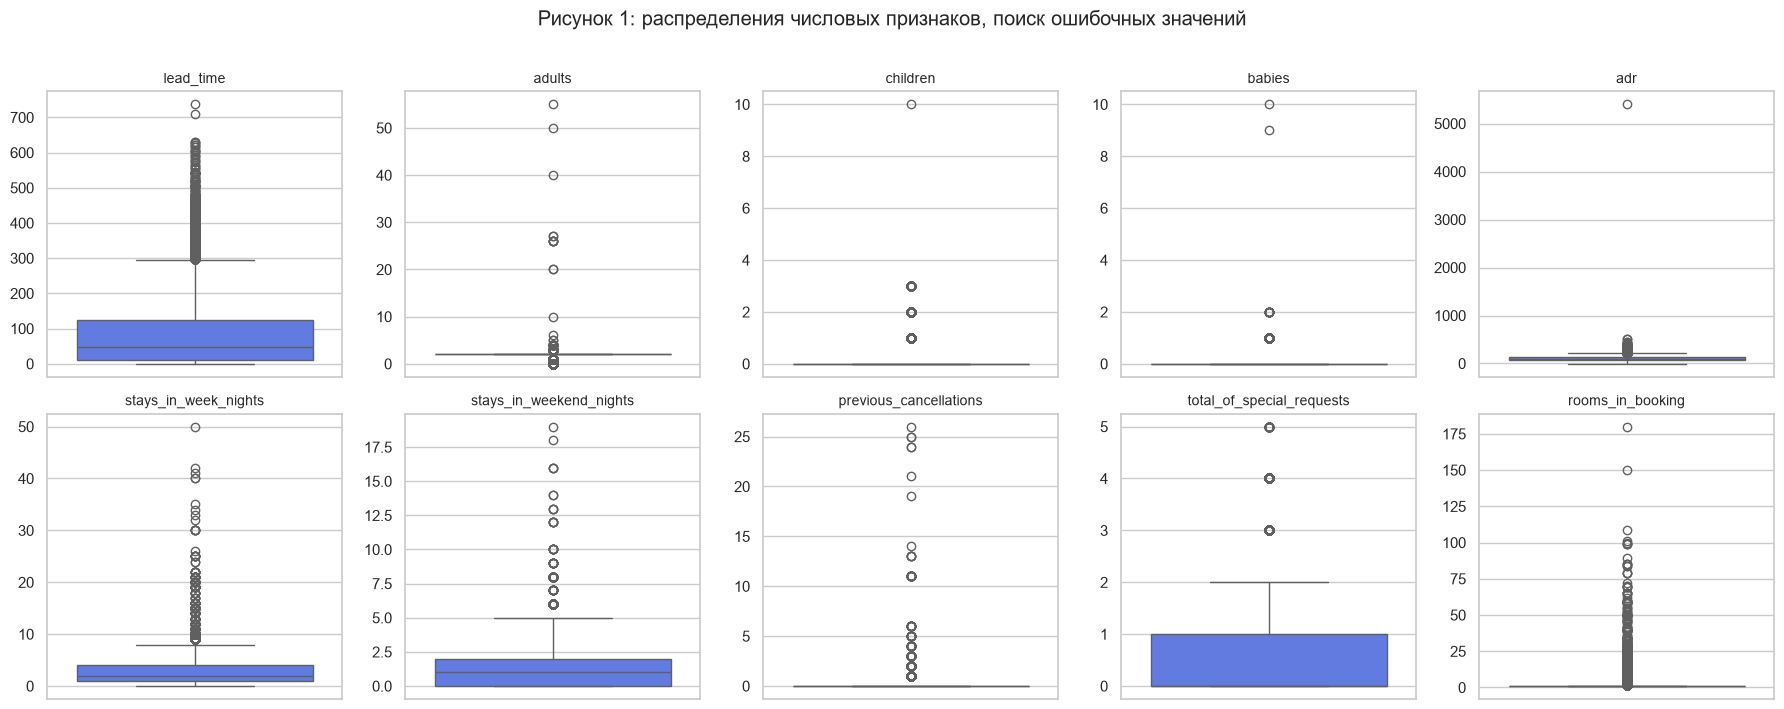

In [19]:
num_cols = ["lead_time", "adults", "children", "babies", "adr",
            "stays_in_week_nights", "stays_in_weekend_nights",
            "previous_cancellations", "total_of_special_requests", "rooms_in_booking"]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#4C6EF5")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")
plt.suptitle("Рисунок 1: распределения числовых признаков, поиск ошибочных значений", y=1.01)
plt.tight_layout()
plt.show()

Точки за усами есть почти у всех признаков, но ошибочными из них являются единицы. Boxplot помечает всё, что дальше полутора межквартильных размахов от ящика, а это ещё не признак ошибки.

Максимальный `lead_time` 737 дней - два года, для групповых заявок и квот туроператоров это нормальный горизонт. У `rooms_in_booking` максимум 180, но это признак, который мы сами создали из размера групповой брони. У `total_of_special_requests` шкала от 0 до 5, выбросов там не бывает по построению: значения 3-5 просто редкие.

Экстремальные значения по составу гостей: 12 броней с числом взрослых больше десяти (максимум 55), одна с десятью детьми, две с девятью и более младенцами. Долгие проживания: 30 броней дольше трёх недель в будни, максимум 50 ночей. История гостя: 39 броней с числом прошлых отмен больше десяти, максимум 26.

Эти значения редкие, но физически возможны: 55 взрослых - групповая заявка, 50 ночей - длительное размещение. Удалять их нет оснований, в модели они растворятся.

Нашлось три типа ошибочных значений: одно отрицательное `adr`, одно значение `adr` 5 400 при медиане 98, и 166 броней с нулевым количеством гостей. Решения по ним приняты в разделе формирования итогового набора признаков.

In [20]:
zero_adults_mask = df['adults'] == 0
zero_adults_count = zero_adults_mask.sum()

print(f"Количество записей с adults == 0: {zero_adults_count} \n")

if zero_adults_count > 0:
    display(
        df.loc[zero_adults_mask, ['hotel', 'adults', 'children', 'babies', 'is_canceled']]
        .head(10)
        .style.set_caption("Таблица 8: Примеры записей с нулевым количеством взрослых")
    )

Количество записей с adults == 0: 385 



,hotel,adults,children,babies,is_canceled
2088,Resort Hotel,0,0,0,0
2224,Resort Hotel,0,0,0,0
2804,Resort Hotel,0,0,0,0
3091,Resort Hotel,0,0,0,0
3099,Resort Hotel,0,0,0,0
3325,Resort Hotel,0,0,0,1
7039,Resort Hotel,0,0,0,1
26491,Resort Hotel,0,0,0,0
26726,Resort Hotel,0,0,0,0
27391,Resort Hotel,0,0,0,0


In [21]:
# Анализ экстремальных значений ADR
adr_negative_count = (df['adr'] < 0).sum()
adr_extreme_count = (df['adr'] > 1000).sum()

print(f"Записей с отрицательным ADR: {adr_negative_count}")
print(f"Записей с ADR > 1000: {adr_extreme_count}")

Записей с отрицательным ADR: 1
Записей с ADR > 1000: 1


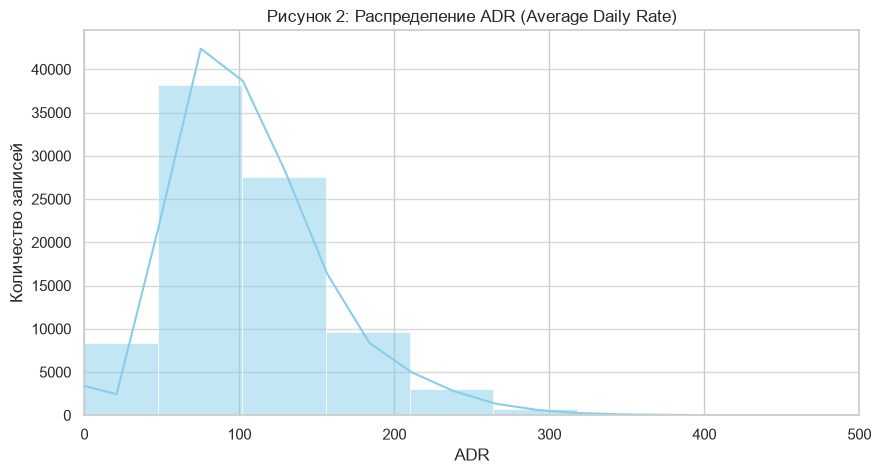

In [57]:
# Визуализация распределения ADR с ограничением оси для наглядности основной массы данных
plt.figure(figsize=(10, 5))
sns.histplot(df['adr'], bins=100, kde=True, color='skyblue')

plt.title('Рисунок 2: Распределение ADR (Average Daily Rate)')
plt.xlabel('ADR')
plt.ylabel('Количество записей')
plt.xlim(0, 500)
plt.grid(axis='y', alpha=0.75)

plt.show()

### Обработка выбросов

Выбросы выявлены по сетке boxplot и проверены по границам правдоподобия. Принятое решение: экстремальные значения сохраняются, обработке подлежат только физически невозможные.

# Связь целевой переменной и признаков

C:\Users\maris\AppData\Local\Temp\ipykernel_62372\2087405073.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='hotel', y='is_canceled', data=df, errorbar=None, palette='muted')


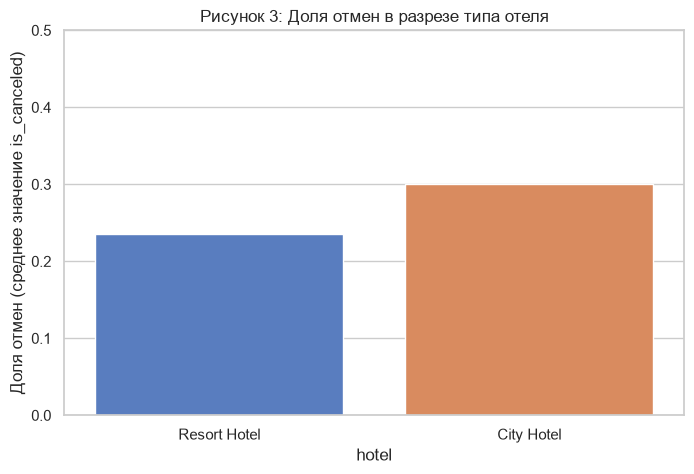

In [24]:
plt.figure(figsize=(8, 5))
sns.barplot(x='hotel', y='is_canceled', data=df, errorbar=None, palette='muted')
plt.title('Рисунок 3: Доля отмен в разрезе типа отеля')
plt.ylabel('Доля отмен (среднее значение is_canceled)')
plt.ylim(0, 0.5)
plt.show()

C:\Users\maris\AppData\Local\Temp\ipykernel_62372\2433202519.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='deposit_type', y='is_canceled', data=df, errorbar=None, palette='muted')


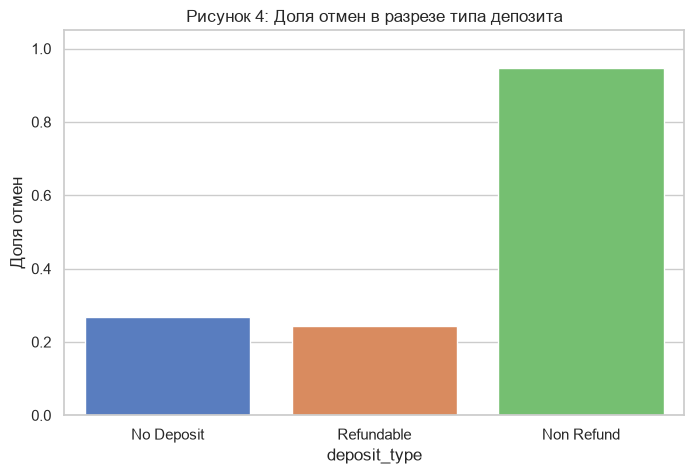

In [25]:
plt.figure(figsize=(8, 5))
sns.barplot(x='deposit_type', y='is_canceled', data=df, errorbar=None, palette='muted')
plt.title('Рисунок 4: Доля отмен в разрезе типа депозита')
plt.ylabel('Доля отмен')
plt.ylim(0, 1.05)
plt.show()

In [26]:
# Поведение каждого категориального признака в отдельности
cat_cols = ['hotel', 'meal', 'market_segment', 'distribution_channel',
            'customer_type', 'reserved_room_type', 'is_repeated_guest']

for col in cat_cols:
    table = (df.groupby(col)['is_canceled']
             .agg(Броней='size', Доля_отмен='mean').round(3)
             .sort_values('Доля_отмен', ascending=False))
    table = table[table['Броней'] >= 100]
    print(f"\n--- {col} ---")
    print(table.to_string())

print(f"\nВ среднем по данным: {df['is_canceled'].mean():.3f}")


--- hotel ---
              Броней  Доля_отмен
hotel                           
City Hotel     53428       0.300
Resort Hotel   33968       0.235

--- meal ---
           Броней  Доля_отмен
meal                         
SC           9481       0.353
FB            360       0.275
HB           9085       0.270
BB          67978       0.265
Undefined     492       0.167

--- market_segment ---
                Броней  Доля_отмен
market_segment                    
Online TA        51618       0.353
Groups            4942       0.270
Aviation           227       0.198
Offline TA/TO    13889       0.149
Direct           11804       0.147
Complementary      702       0.125
Corporate         4212       0.121

--- distribution_channel ---
                      Броней  Доля_отмен
distribution_channel                    
TA/TO                  69141       0.310
GDS                      181       0.199
Direct                 12988       0.148
Corporate               5081       0.128

--- customer_

In [27]:
# Бинарные разрезы по счётчикам истории гостя
for col in ['previous_cancellations', 'previous_bookings_not_canceled',
            'total_of_special_requests', 'booking_changes']:
    has = df[col] > 0
    print(f"{col:32s} >0: {has.sum():6,} броней, отмен {df.loc[has, 'is_canceled'].mean():.3f} | "
          f"=0: {(~has).sum():6,}, отмен {df.loc[~has, 'is_canceled'].mean():.3f}")

previous_cancellations           >0:  1,685 броней, отмен 0.679 | =0: 85,711, отмен 0.267
previous_bookings_not_canceled   >0:  3,545 броней, отмен 0.050 | =0: 83,851, отмен 0.284
total_of_special_requests        >0: 43,502 броней, отмен 0.217 | =0: 43,894, отмен 0.332
booking_changes                  >0: 15,902 броней, отмен 0.155 | =0: 71,494, отмен 0.302


### Выводы по отдельным признакам

Сильнее всего отмену предсказывает история гостя. Если он раньше доезжал, то отменяет в 5.0% случаев против 28.4% у остальных; если раньше отменял – в 67.9%. Это единственные три признака, которые описывают человека, а не параметры брони. Мешает одно: хоть какая-то история есть только у 5.8% записей.

Канал продаж, в отличие от истории, работает на всём массиве и даёт устойчивый трёхкратный разрыв – 35.3% у онлайн-турагентств против 12.1% у корпоративных броней. При этом `market_segment` и `distribution_channel` описывают одно и то же разными словами: 51 316 из 51 618 броней `Online TA` идут каналом `TA/TO`.

Отдельно по питанию. Категории `SC` и `Undefined` выглядят синонимами, "без питания" и "не указано". Доли отмен – 35.3% и 16.7%.

Самое неприятное обнаружилось на пересечении признаков. Бронь через онлайн-турагентство, у гостя нет истории, специальных пожеланий нет: 18 361 запись, 21% данных, доля отмен 53%. Все сильные сигналы молчат одновременно.

Остальное ожидаемо – городской отель 30.0% против курортного 23.5%, тип клиента `Transient` 30.1% против `Group` 9.9%, типы номеров различаются слабо.

C:\Users\maris\AppData\Local\Temp\ipykernel_62372\2211733654.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='lead_time_bin', y='is_canceled', data=df, errorbar=None, palette='muted')


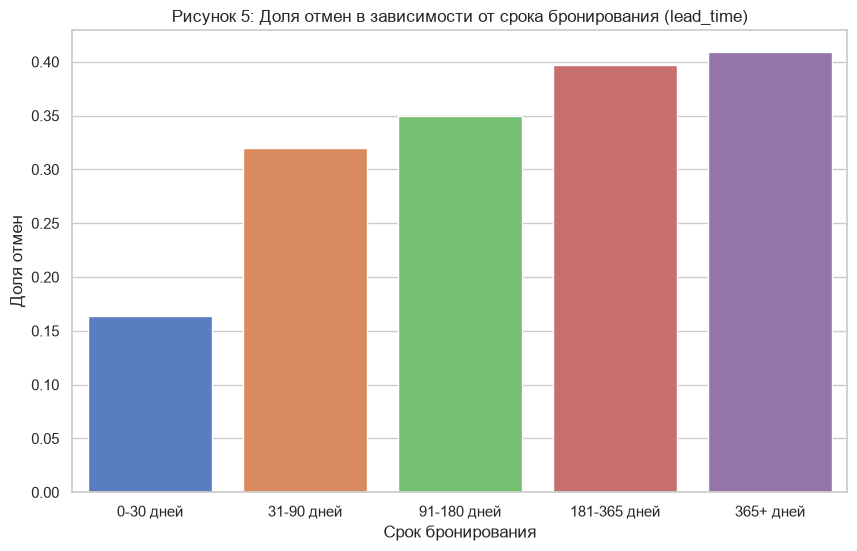

In [28]:
df['lead_time_bin'] = pd.cut(df['lead_time'],
                             bins=[-1, 30, 90, 180, 365, 10000],
                             labels=['0-30 дней', '31-90 дней', '91-180 дней', '181-365 дней', '365+ дней'])

plt.figure(figsize=(10, 6))
sns.barplot(x='lead_time_bin', y='is_canceled', data=df, errorbar=None, palette='muted')
plt.title('Рисунок 5: Доля отмен в зависимости от срока бронирования (lead_time)')
plt.ylabel('Доля отмен')
plt.xlabel('Срок бронирования')
plt.show()

In [29]:
print(df['lead_time_bin'].isna().sum())   # должно быть 0

0


,Броней,Доля_отмен
adr,,
0 (бесплатно),1778,0.104
1-50,8079,0.159
51-80,19141,0.225
81-110,23405,0.276
111-150,19879,0.326
151-200,10395,0.340
200+,4718,0.376


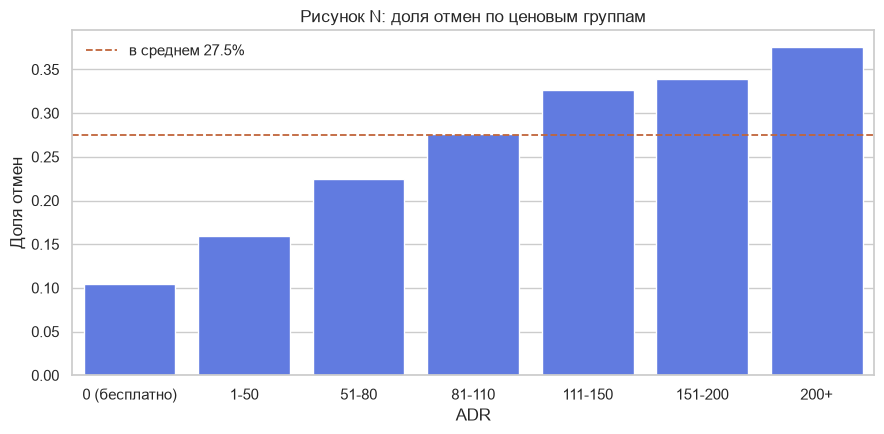

In [61]:
# Связь цены с отменами
price_bins = pd.cut(df['adr'], [-1, 0, 50, 80, 110, 150, 200, 10000],
                    labels=['0 (бесплатно)', '1-50', '51-80', '81-110',
                            '111-150', '151-200', '200+'])

price_table = (df.groupby(price_bins, observed=True)['is_canceled']
               .agg(Броней='size', Доля_отмен='mean').round(3))
display(price_table.style.set_caption("Таблица N: доля отмен по ценовым группам"))

plt.figure(figsize=(9, 4.5))
sns.barplot(x=price_bins, y=df['is_canceled'], errorbar=None, color='#4C6EF5')
plt.axhline(df['is_canceled'].mean(), color='#C0653A', ls='--', lw=1.3,
            label=f"в среднем {df['is_canceled'].mean():.1%}")
plt.title('Рисунок N: доля отмен по ценовым группам')
plt.xlabel('ADR')
plt.ylabel('Доля отмен')
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

Чем дороже бронь, тем чаще её отменяют: от 10.4% у бесплатных размещений до 37.6% у броней дороже 200. Рост монотонный на всём диапазоне.

Корреляция `adr` с отменой составляет 0.128 и эту связь недооценивает: зависимость нелинейна, основной подъём приходится на участок от 50 до 150, где лежит 71% данных.

Проверка на смешение с типом отеля: внутри City Hotel рост идёт с 20.8% до 35.8%, внутри Resort Hotel - с 15.6% до 38.5%. Эффект цены сохраняется в обоих отелях, то есть не объясняется тем, что городской отель дороже и отменяется чаще.

Отдельная группа - бесплатные размещения с нулевым `adr`. Их 1 778, доля отмен 10.4%, то есть вдвое с лишним ниже среднего. Нулевая цена здесь не пропуск, а служебное или комплиментарное размещение, и признак несёт сигнал.

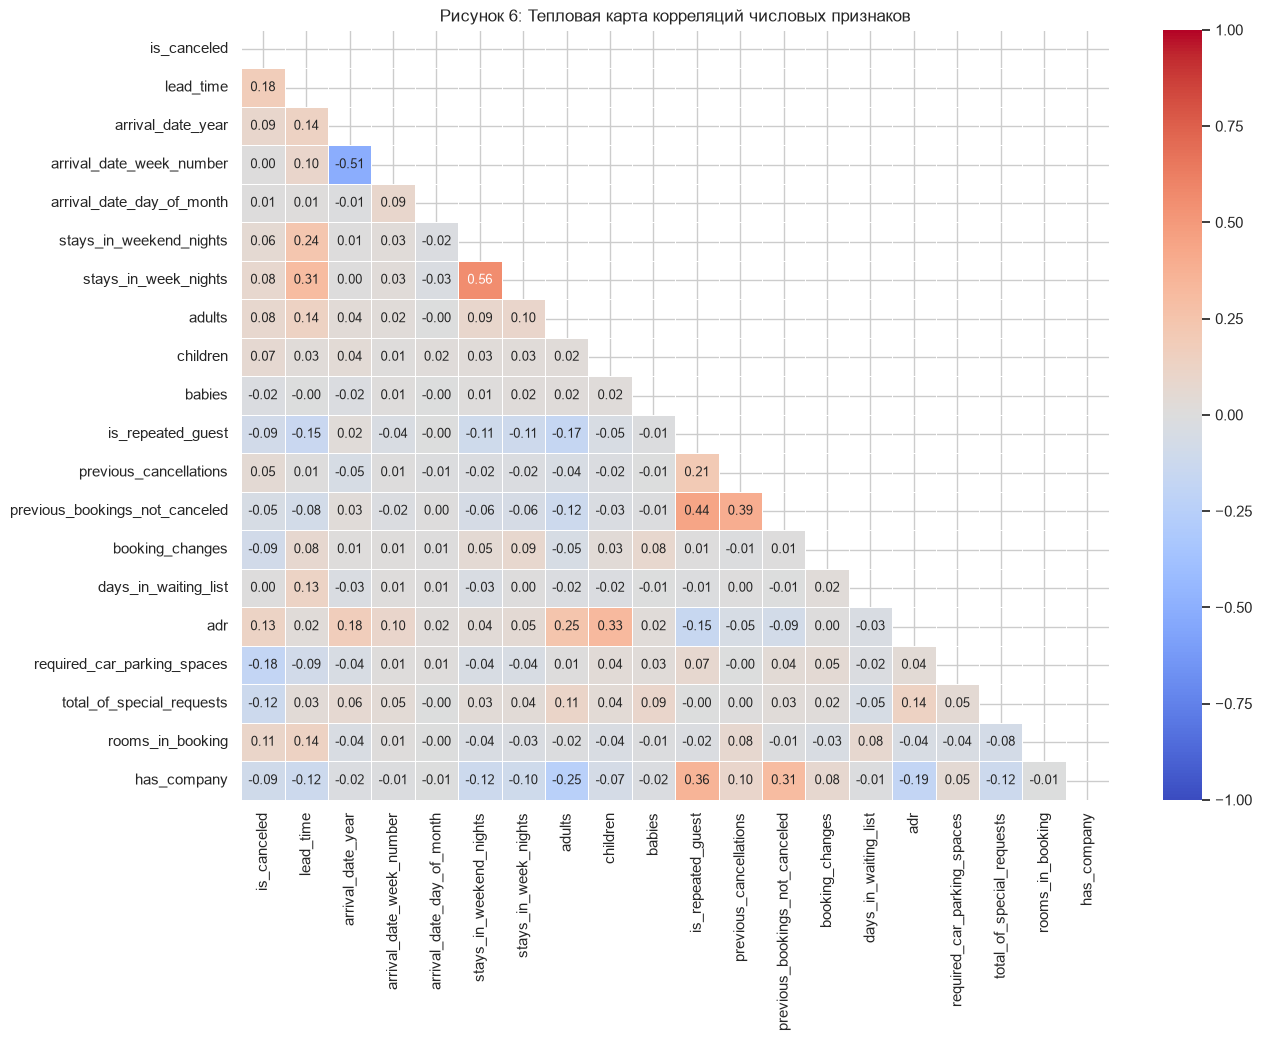

In [30]:
# Тепловая карта корреляций только для числовых признаков
numeric_cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(14, 10))
correlation_matrix = df[numeric_cols].corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 9}
)
plt.title('Рисунок 6: Тепловая карта корреляций числовых признаков')
plt.show()

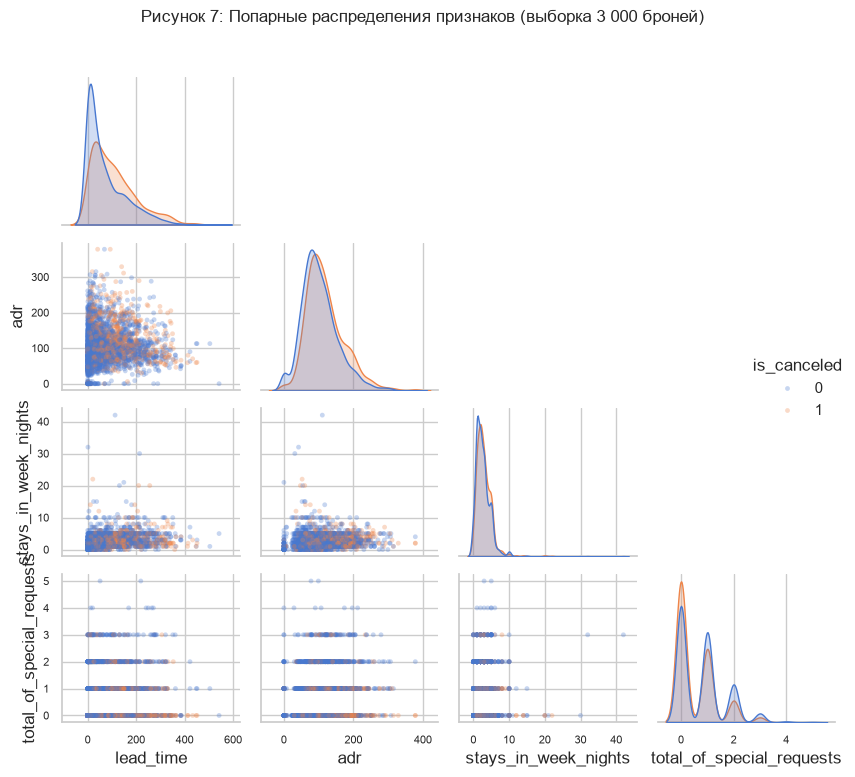

In [31]:
# Попарные распределения признаков
pair_cols = ["lead_time", "adr", "stays_in_week_nights", "total_of_special_requests"]

g = sns.pairplot(df[pair_cols + ["is_canceled"]].sample(3000, random_state=42),
                 hue="is_canceled", corner=True, height=1.9,
                 plot_kws={"alpha": 0.3, "s": 12, "edgecolor": "none"},
                 diag_kws={"common_norm": False})
g.figure.suptitle("Рисунок 7: Попарные распределения признаков (выборка 3 000 броней)",
                  y=1.02, fontsize=12)
for ax in g.axes.flat:
    if ax is not None:
        ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

### Выводы по попарным распределениям

Ни одна пара признаков не делит брони на отменённые и состоявшиеся: синие и оранжевые точки лежат вперемешку на всех графиках. Разница заметна только на диагонали, где показано распределение каждого признака по отдельности. Сильнее всего она видна у `lead_time`: оранжевая кривая сдвинута вправо, то есть отменённые брони делают заранее, а не перед самым заездом.

Простая формула вида "если срок больше N дней и цена выше M - значит отменят" работать не будет, таких границ в данных нет. Значит, нужны модели, которые умеют учитывать сочетания признаков, а не каждый по отдельности.

# Анализ параметров с возможной утечкой данных

In [32]:
print("Таблица 9: Количество записей по типу депозита")
display(df['deposit_type'].value_counts().to_frame())

Таблица 9: Количество записей по типу депозита


,count
deposit_type,
No Deposit,86251
Non Refund,1038
Refundable,107


In [33]:
print("Таблица 10: Доля отмен для Non Refund по отелям")
non_refund_data = df[df['deposit_type'] == 'Non Refund']
display(non_refund_data.groupby('hotel')['is_canceled'].mean().to_frame())

Таблица 10: Доля отмен для Non Refund по отелям


,is_canceled
hotel,
City Hotel,0.971598
Resort Hotel,0.839378


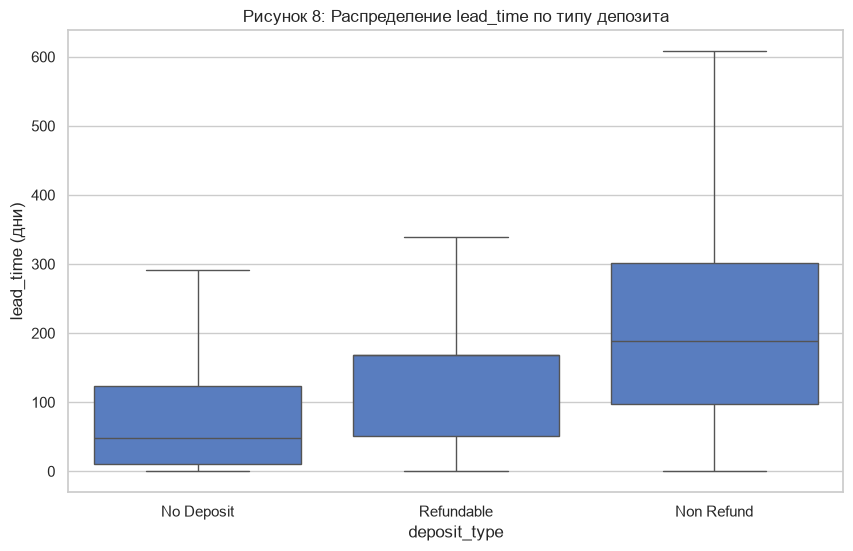

In [34]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='deposit_type', y='lead_time', data=df, showfliers=False)
plt.title('Рисунок 8: Распределение lead_time по типу депозита')
plt.ylabel('lead_time (дни)')
plt.show()

In [35]:
print("Таблица 11: Среднее количество изменений брони по типу депозита")
display(df.groupby('deposit_type')['booking_changes'].mean().to_frame())

Таблица 11: Среднее количество изменений брони по типу депозита


,booking_changes
deposit_type,
No Deposit,0.273249
Non Refund,0.085742
Refundable,0.747664


In [36]:
print("Таблица 12: Доля отмен по deposit_type")
display(df.groupby('deposit_type')['is_canceled'].mean().to_frame())

Таблица 12: Доля отмен по deposit_type


,is_canceled
deposit_type,
No Deposit,0.266849
Non Refund,0.947013
Refundable,0.242991


In [37]:
# Пробуем сгладить влияние параметра с утечкой
df['has_deposit'] = (df['deposit_type'] != 'No Deposit').astype(int)

print("Таблица 13: Доля отмен по has_deposit")
display(df.groupby('has_deposit')['is_canceled'].mean().to_frame())

Таблица 13: Доля отмен по has_deposit


,is_canceled
has_deposit,
0,0.266849
1,0.881223


In [38]:
leakage_candidates = [
    'assigned_room_type',      # может измениться при заезде
    'reservation_status_date', # точно после бронирования
    'booking_changes',         # меняется со временем
    'days_in_waiting_list'     # меняется со временем
]

print("Анализ потенциальных утечек данных")

for col in leakage_candidates:
    print(f"--- {col} ---")
    print(f"Уникальных значений: {df[col].nunique()}")
    print(f"Первые 10 значений:")
    print(df[col].value_counts().head(3))
    print()

Анализ потенциальных утечек данных
--- assigned_room_type ---
Уникальных значений: 12
Первые 10 значений:
assigned_room_type
A    46313
D    22432
E     7195
Name: count, dtype: int64

--- reservation_status_date ---
Уникальных значений: 926
Первые 10 значений:
reservation_status_date
2016-02-14    211
2017-05-25    205
2015-10-21    199
Name: count, dtype: int64

--- booking_changes ---
Уникальных значений: 21
Первые 10 значений:
booking_changes
0    71494
1    10902
2     3508
Name: count, dtype: int64

--- days_in_waiting_list ---
Уникальных значений: 128
Первые 10 значений:
days_in_waiting_list
0     86536
63       53
87       25
Name: count, dtype: int64



In [39]:
room_comparison = pd.crosstab(
    df['reserved_room_type'],
    df['assigned_room_type'],
    margins=True
)

display(room_comparison.style.set_caption("Таблица 14: Соответствие зарезервированного и назначенного типа номера"))

room_changed = (df['reserved_room_type'] != df['assigned_room_type']).mean()
print()
print(f"Доля бронирований, где тип номера изменился: {room_changed:.4%}")

assigned_room_type,A,B,C,D,E,F,G,H,I,K,L,P,All
reserved_room_type,,,,,,,,,,,,,
A,45879,894,1256,6410,1035,390,178,94,209,207,0,0,56552
B,106,874,0,5,2,2,8,0,0,2,0,0,999
C,5,2,867,6,4,2,10,9,10,0,0,0,915
D,296,27,33,15984,657,199,82,9,67,44,0,0,17398
E,15,3,6,22,5462,383,98,4,40,16,0,0,6049
F,6,17,0,4,31,2636,113,3,10,3,0,0,2823
G,5,2,2,0,4,14,1999,7,15,4,0,0,2052
H,0,0,0,1,0,0,10,579,6,0,0,0,596
L,1,1,1,0,0,1,0,1,0,0,1,0,6



Доля бронирований, где тип номера изменился: 14.9995%


In [40]:
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4,
    'May': 5, 'June': 6, 'July': 7, 'August': 8,
    'September': 9, 'October': 10, 'November': 11, 'December': 12
}

df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'].map(month_map).astype(str) + '-' +
    df['arrival_date_day_of_month'].astype(str)
)

df['booking_date'] = df['arrival_date'] - pd.to_timedelta(df['lead_time'], unit='D')

print(f"Диапазон: {df['booking_date'].min().date()} до {df['booking_date'].max().date()}")

Диапазон: 2013-06-24 до 2017-08-31


In [41]:
print("Анализ reservation_status_date \n")

df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])
print(f"Диапазон дат изменения статуса: {df['reservation_status_date'].min()} до {df['reservation_status_date'].max()}")
print(f"Диапазон дат бронирования (booking_date): {df['booking_date'].min()} до {df['booking_date'].max()}")

# Проверяем, есть ли случаи, когда статус изменился ДО бронирования
status_before_booking = (df['reservation_status_date'] < df['booking_date']).sum()
print(f"Количество записей, где статус изменился ДО бронирования: {status_before_booking}")

# Проверяем, есть ли случаи, когда статус изменился ПОСЛЕ заезда
status_after_arrival = (df['reservation_status_date'] > df['arrival_date']).sum()
print(f"Количество записей, где статус изменился ПОСЛЕ заезда: {status_after_arrival}")

Анализ reservation_status_date 

Диапазон дат изменения статуса: 2014-10-17 00:00:00 до 2017-09-14 00:00:00
Диапазон дат бронирования (booking_date): 2013-06-24 00:00:00 до 2017-08-31 00:00:00
Количество записей, где статус изменился ДО бронирования: 0
Количество записей, где статус изменился ПОСЛЕ заезда: 62726


In [42]:
# Сравнительная статистика lead_time для отмененных и успешных бронирований
lead_time_stats = df.groupby('is_canceled')['lead_time'].agg(['count', 'mean', 'median', 'max']).round(1)

# Переименуем индексы для наглядности
lead_time_stats.index = ['0: Успешный заезд', '1: Отмена / No-Show']

display(lead_time_stats.style.set_caption("Таблица 15: Сравнение сроков бронирования по факту заезда"))

,count,mean,median,max
0: Успешный заезд,63371,70.100,38.000,737
1: Отмена / No-Show,24025,105.700,80.000,629


C:\Users\maris\AppData\Local\Temp\ipykernel_62372\3406199913.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
findfont: Failed to find font weight semibold for Arial, now using 700.


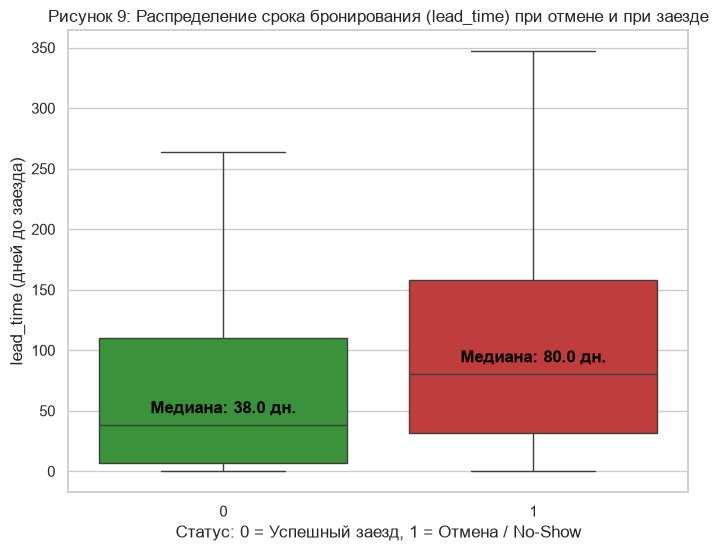

In [43]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    x='is_canceled',
    y='lead_time',
    data=df,
    showfliers=False,
    palette=['#2ca02c', '#d62728']
)

plt.title('Рисунок 9: Распределение срока бронирования (lead_time) при отмене и при заезде')
plt.xlabel('Статус: 0 = Успешный заезд, 1 = Отмена / No-Show')
plt.ylabel('lead_time (дней до заезда)')

medians = df.groupby('is_canceled')['lead_time'].median().values
for i, median in enumerate(medians):
    plt.text(i, median + 10, f'Медиана: {median} дн.',
             horizontalalignment='center', size='medium', color='black', weight='semibold')

plt.show()

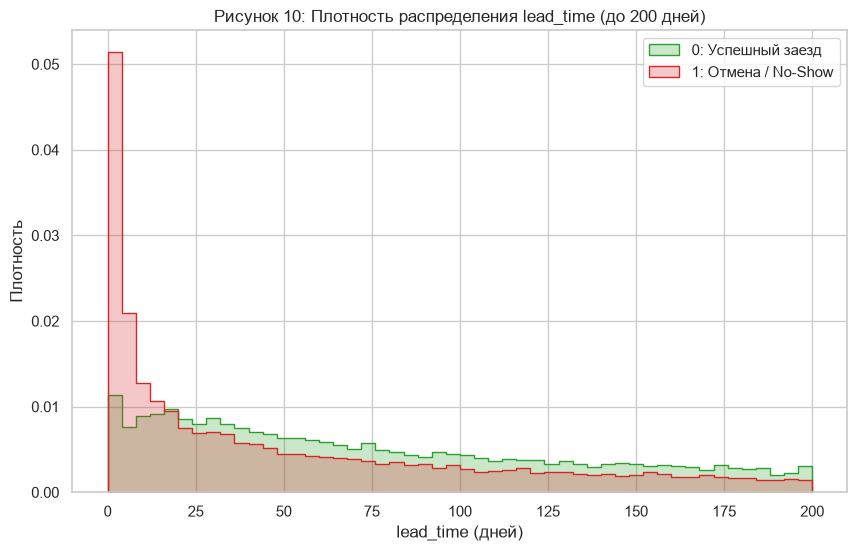

In [44]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df[df['lead_time'] <= 200], # Фильтруем экстремальные хвосты
    x='lead_time',
    hue='is_canceled',
    element='step',
    stat='density',
    common_norm=False,
    palette=['#d62728', '#2ca02c']
)

plt.title('Рисунок 10: Плотность распределения lead_time (до 200 дней)')
plt.xlabel('lead_time (дней)')
plt.ylabel('Плотность')
plt.legend(['0: Успешный заезд', '1: Отмена / No-Show'])
plt.show()

In [45]:
print("Пропусков в данных:", df.isna().sum().sum())
print("Строк:", len(df), "| столбцов:", df.shape[1])

Пропусков в данных: 0
Строк: 87396 | столбцов: 37


In [46]:
#Анализ признака required_car_parking_spaces
display(df['required_car_parking_spaces'].value_counts().to_frame()
        .style.set_caption("Таблица 16: Количество запросов парковочных мест"))

print("\n")

cross_parking = pd.crosstab(df['required_car_parking_spaces'], df['is_canceled'], margins=True)
display(cross_parking.style.set_caption("Таблица 17: Связь парковки с отменами"))

print("\n")

parking_cancel_rate = df.groupby('required_car_parking_spaces')['is_canceled'].agg(['count', 'mean']).round(4)
display(parking_cancel_rate.style.set_caption("Таблица 18: Доля отмен по количеству запрошенных мест"))

print("\n")

# есть ли отмены среди тех, кто запросил парковку?
parking_requests = df[df['required_car_parking_spaces'] > 0]
print(f"Всего броней с запросом парковки: {len(parking_requests)}")
print(f"Из них отменено: {parking_requests['is_canceled'].sum()}")
print(f"Доля отмен: {parking_requests['is_canceled'].mean():.4f}")

,count
required_car_parking_spaces,
0,80083
1,7280
2,28
3,3
8,2


is_canceled,0,1,All
required_car_parking_spaces,,,
0,56058,24025,80083
1,7280,0,7280
2,28,0,28
3,3,0,3
8,2,0,2
All,63371,24025,87396


,count,mean
required_car_parking_spaces,,
0,80083,0.300
1,7280,0.000
2,28,0.000
3,3,0.000
8,2,0.000




Всего броней с запросом парковки: 7313
Из них отменено: 0
Доля отмен: 0.0000


required_car_parking_spaces — target leakage. Признак подлежит удалению.

In [47]:
changes_stats = df.groupby('is_canceled')['booking_changes'].agg(['count', 'mean', 'median', 'max']).round(3)
changes_stats.index = ['0: Успешный заезд', '1: Отмена / No-Show']
display(changes_stats.style.set_caption("Таблица 19: Статистика booking_changes по группам"))

print("\n")

changes_crosstab = pd.crosstab(df['booking_changes'], df['is_canceled'], margins=True)
display(changes_crosstab.style.set_caption("Таблица 20: booking_changes против is_canceled"))

canceled_with_changes = df[(df['is_canceled'] == 1) & (df['booking_changes'] > 0)].shape[0]
print(f"Отменённых броней с ненулевым числом изменений: {canceled_with_changes}")

,count,mean,median,max
0: Успешный заезд,63371,0.314,0.000,21
1: Отмена / No-Show,24025,0.161,0.000,16


is_canceled,0,1,All
booking_changes,,,
0,49926,21568,71494
1,9391,1511,10902
2,2804,704,3508
3,744,131,875
4,293,63,356
5,96,20,116
6,42,17,59
7,28,3,31
8,13,4,17


Отменённых броней с ненулевым числом изменений: 2457


In [48]:
waiting_stats = df.groupby('is_canceled')['days_in_waiting_list'].agg(['count', 'mean', 'median', 'max']).round(3)
waiting_stats.index = ['0: Успешный заезд', '1: Отмена / No-Show']
display(waiting_stats.style.set_caption("Таблица 21: Статистика days_in_waiting_list по группам"))

print("\n")

was_in_waiting_list = (df['days_in_waiting_list'] > 0).astype(int)
waiting_crosstab = pd.crosstab(was_in_waiting_list, df['is_canceled'], margins=True)
display(waiting_crosstab.style.set_caption("Таблица 22: was_in_waiting_list против is_canceled"))

canceled_with_waiting = df[(df['is_canceled'] == 1) & (df['days_in_waiting_list'] > 0)].shape[0]
print(f"Отменённых броней, побывавших в листе ожидания: {canceled_with_waiting}")

,count,mean,median,max
0: Успешный заезд,63371,0.722,0.000,379
1: Отмена / No-Show,24025,0.822,0.000,391


is_canceled,0,1,All
days_in_waiting_list,,,
0,62805,23731,86536
1,566,294,860
All,63371,24025,87396


Отменённых броней, побывавших в листе ожидания: 294


In [49]:
requests_stats = df.groupby('is_canceled')['total_of_special_requests'].agg(['count', 'mean', 'median', 'max']).round(3)
requests_stats.index = ['0: Успешный заезд', '1: Отмена / No-Show']
display(requests_stats.style.set_caption("Таблица 23: Статистика total_of_special_requests по группам"))

print("\n")

requests_crosstab = pd.crosstab(df['total_of_special_requests'], df['is_canceled'], margins=True)
display(requests_crosstab.style.set_caption("Таблица 24: total_of_special_requests против is_canceled"))

canceled_with_requests = df[(df['is_canceled'] == 1) & (df['total_of_special_requests'] > 0)].shape[0]
print(f"Отменённых броней со специальными запросами: {canceled_with_requests}")

,count,mean,median,max
0: Успешный заезд,63371,0.760,1.000,5
1: Отмена / No-Show,24025,0.536,0.000,5


is_canceled,0,1,All
total_of_special_requests,,,
0,29320,14574,43894
1,22514,6503,29017
2,9297,2515,11812
3,1920,397,2317
4,286,34,320
5,34,2,36
All,63371,24025,87396


Отменённых броней со специальными запросами: 9451


# Формирование итогового набора признаков

In [50]:
LEAKAGE_COLUMNS = [
    'reservation_status',
    'reservation_status_date',
    'assigned_room_type',
    'deposit_type',
    'required_car_parking_spaces',
    'booking_changes',
]

df_clean = df.copy()
print(f"Исходный размер: {df_clean.shape}")

df_clean = df_clean.drop(columns=LEAKAGE_COLUMNS)
print(f"После удаления признаков с утечкой: {df_clean.shape}")

Исходный размер: (87396, 37)
После удаления признаков с утечкой: (87396, 31)


In [51]:
zero_guests_mask = (
    (df_clean['adults'] == 0) &
    (df_clean['children'] == 0) &
    (df_clean['babies'] == 0)
)

print(f"Строк к удалению (ноль гостей): {zero_guests_mask.sum()}")

df_clean = df_clean[~zero_guests_mask]
print(f"После удаления строк с нулём гостей: {df_clean.shape}")

Строк к удалению (ноль гостей): 166
После удаления строк с нулём гостей: (87230, 31)


In [52]:
negative_adr = (df_clean['adr'] < 0).sum()
df_clean.loc[df_clean['adr'] < 0, 'adr'] = 0
print(f"Исправлено отрицательных значений adr: {negative_adr}\n")

print(f"adr: минимум {df_clean['adr'].min():.2f}, медиана {df_clean['adr'].median():.2f}, "
      f"p99 {df_clean['adr'].quantile(0.99):.2f}, максимум {df_clean['adr'].max():.0f}")
print(f"Значений выше p99: {(df_clean['adr'] > df_clean['adr'].quantile(0.99)).sum()} (1.00%)")
print(f"Нулевых: {(df_clean['adr'] == 0).sum()} ({(df_clean['adr'] == 0).mean():.2%}), "
      f"доля отмен в них {df_clean.loc[df_clean['adr'] == 0, 'is_canceled'].mean():.1%}")

Исправлено отрицательных значений adr: 1

adr: минимум 0.00, медиана 98.20, p99 261.62, максимум 5400
Значений выше p99: 873 (1.00%)
Нулевых: 1644 (1.88%), доля отмен в них 10.3%


### Решение по признаку adr

Обработано одно отрицательное значение: замена на ноль как единичная ошибка знака.

Верхний хвост распределения не усекается. Решение принято по трём основаниям.

Крайние значения правдоподобны. Между p95 и p99 лежат реальные дорогие брони, а не ошибки ввода. Усечение по p99 изменило бы 873 значения, то есть 1% данных.

Усечение не влияет на выводы. Корреляция `adr` с целевой переменной составляет 0.127 без усечения и 0.135 с усечением, среднее меняется со 106.52 на 106.14. Изменение реальных значений не окупается.

Дорогой сегмент нужен для анализа. Карточка темы предусматривает разбор ошибок модели по ценовым сегментам, а усечение убирает именно верхний сегмент.

Единственное экстремальное наблюдение (`adr` 5400 при медиане 98.2) сохраняется и учитывается при интерпретации, но не удаляется.

Нулевые значения `adr` (1 644 брони, 1.88%) также сохраняются: это бесплатные и служебные размещения, доля отмен в них 10.3% против 27.5% в среднем. Признак несёт сигнал.

In [53]:
# days_in_waiting_list: 99% нулей, информативен сам факт попадания в лист ожидания
df_clean['was_in_waiting_list'] = (df_clean['days_in_waiting_list'] > 0).astype(int)
df_clean = df_clean.drop(columns=['days_in_waiting_list'])

print(df_clean.groupby('was_in_waiting_list')['is_canceled']
      .agg(Броней='size', Доля_отмен='mean').round(3).to_string())

                     Броней  Доля_отмен
was_in_waiting_list                    
0                     86375       0.275
1                       855       0.344


# Реестр утечек данных

Критерий пригодности признака: значение известно и зафиксировано в момент подтверждения брони. Согласно спецификации проекта, именно в этот момент выполняется скоринг: сервис оценивает риск отмены сразу после подтверждения брони и имеет доступ только к полям, доступным в этот момент.

Все приведённые ниже числа посчитаны на данных после удаления дубликатов (87 396 броней).

## Признаки, исключённые из модели

| Признак | Тип утечки |
| :-- | :-- |
| `reservation_status` | Прямая утечка таргета |
| `reservation_status_date` | Постфактум-информация |
| `assigned_room_type` | Постфактум-информация |
| `deposit_type` | Требует проверки, см. п. 4 |
| `required_car_parking_spaces` | Постфактум-заполнение |
| `booking_changes` | Постфактум-накопление |

### Обоснования

1. `reservation_status`. Кросс-таблица с целевой переменной показывает точное совпадение: `is_canceled == 1` соответствует статусам `Canceled` (23 011 записей) и `No-Show` (1 014 записей), `is_canceled == 0` соответствует `Check-Out` (63 371 запись). Признак является другой формой записи таргета.

2. `reservation_status_date`. Проверка хронологии показала: ни одна запись не имеет даты изменения статуса раньше даты создания брони, а у 62 726 записей дата изменения статуса следует после даты заезда. Значение становится известным только после исхода.

3. `assigned_room_type`. Сопоставление с `reserved_room_type` показало расхождения в 15.00% бронирований (13 109 записей): фактический номер определяется при заселении. Модель не может знать это значение в момент подтверждения брони.

4. `deposit_type`. Экономическая логика предполагает, что невозвратный депозит снижает склонность к отмене, однако доля отмен в категории `Non Refund` составляет 94.7%. Такие брони имеют существенно больший срок до заезда (медиана `lead_time` 188.5 дня против 49 по всем броням) и практически нулевое число изменений (среднее 0.09). Это согласуется с гипотезой о присвоении статуса системой после факта отмены, но прямого доказательства утечки данные не дают. Решение о включении признака принимается на следующем чекпойнте по результатам сравнения моделей с признаком и без него.

5. `required_car_parking_spaces`. Абсолютный ноль отмен на выборке из 7 313 броней не объясняется поведением: даже при вероятности отмены 1% шанс наблюдать ноль отмен составляет порядка 10⁻³². Все бронирования с запросом парковки имеют статус `Check-Out`, следовательно, значение фиксируется при фактическом заселении.

6. `booking_changes`. Ненулевые значения встречаются у 2 457 отменённых броней, что доказывает фиксацию изменений в течение жизни брони, после подтверждения. В момент скоринга новой брони значение признака всегда равно нулю, поэтому обучение на финальных значениях создаёт рассогласование между обучением и инференсом. Наблюдаемое снижение доли отмен при ненулевых изменениях (15.5% против 30.2% при нуле) является survival bias: брони, дожившие до заезда, успевают накопить изменения.

Итог: из 32 исходных столбцов 6 исключены как содержащие утечку или требующие проверки, 1 преобразован в бинарный признак, остальные пригодны для моделирования.

# Выводы по результатам разведочного анализа

## Дублирование записей

Основной дефект исходных данных – дублирование. Полными копиями являются 31 994 строки из 119 390, то есть 26.80% датасета. Происхождение дубликатов производственное: система учёта хранит номеро-брони, поэтому заявка на несколько номеров записывается отдельной строкой на каждый номер. Максимальная группа содержит 180 идентичных строк. На сегменты `Groups` и `Offline TA/TO` приходится 78.8% всего объёма копий.

Без удаления дубликатов искажается большинство выводов о признаках. Базовая доля отмен составила бы 37.0% вместо 27.5%, тариф `Non Refund` покрывал бы 12.2% данных вместо 1.2%, корреляция цены с целевой переменной оценивалась бы в 0.048 вместо 0.128. В последнем случае заключение об отсутствии связи цены с отменами являлось бы прямым следствием дублирования.

Информация о размере заявки сохранена: перед дедупликацией она записана в признак `rooms_in_booking`. Доля отмен по нему возрастает с 26.2% для одиночных броней до 93.9% для заявок от 51 номера.

## Пропуски и ошибочные значения

Пропуски занимают 3.29% ячеек и сосредоточены в четырёх столбцах из 32, при этом 86.7% их объёма приходится на `company`. Механизмы возникновения различны, что определяет различие в обработке.

Пропуск `agent` объясняется каналом продаж: 86.1% для корпоративных броней против 1.7% для броней через турагентства. Пропуск `country` предиктивен сам по себе: такие брони отменяются в 7.5% случаев против 27.6% у остальных. Заполнение модальным значением отклонено: мода `country` – код `PRT` с долей отмен 35.7%, подстановка внесла бы сигнал противоположного знака.

Ошибочные значения представлены одним отрицательным `adr` и 166 бронями с нулевым числом гостей. Крайние значения, отмеченные на диаграммах размаха, в большинстве правдоподобны: срок бронирования в два года соответствует практике групповых заявок, шкала специальных пожеланий от 0 до 5 выбросов не предполагает. Единственное экстремальное наблюдение (`adr` 5 400 при медиане 98) сохранено: усечение по 99-му перцентилю затронуло бы 873 реальных значения без изменения выводов.

Целевая переменная заполнена полностью, принимает значения 0 и 1, согласована с `reservation_status` без исключений. Переменная объединяет два исхода – отмену и неявку гостя, что определяет формулировку задачи: прогнозируется факт использования номера, а не только отмена брони.

## Утечки целевой переменной

Пять признаков содержат информацию, недоступную в момент подтверждения брони, и исключаются из обучающего набора: `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`, `required_car_parking_spaces`. Последний выявлен при анализе нулевых значений: среди 7 313 броней с запрошенным парковочным местом отменённых нет, все имеют статус `Check-Out`. Полное разделение классов на выборке такого объёма указывает на фиксацию значения при заселении.

Статус признака `deposit_type` не определён. Доля отмен в категории `Non Refund` составляет 94.7%, что противоречит экономической логике. Версия о присвоении метки после факта отмены данными не подтверждается: `Non Refund` отмечен у 4.1% отмен и у 0.6% неявок, 55 таких броней завершились заездом. Решение принимается на следующем этапе по результатам сравнения моделей с признаком и без него.

## Предсказательная способность признаков

Линейные связи с целевой переменной слабые: ни одна корреляция не превышает 0.19 по модулю, попарные распределения классы не разделяют. Нелинейные зависимости при этом выражены существенно сильнее.

Срок бронирования остаётся основным предиктором: доля отмен возрастает с 8.4% для броней за неделю до заезда до 39.7% для броней за период от полугода до года, основной прирост приходится на первые тридцать дней. Цена демонстрирует монотонный рост доли отмен с 10.4% у бесплатных размещений до 37.6% у броней дороже 200; эффект сохраняется внутри каждого отеля в отдельности. Канал продаж даёт трёхкратный разрыв между онлайн-турагентствами и корпоративными бронями.

Наибольшей предсказательной силой обладает история гостя: при наличии прошлых успешных заездов доля отмен составляет 5.0%, при наличии прошлых отмен – 67.9%. Применимость группы ограничена: история присутствует у 5.8% броней.

## Границы применимости

Выявлен сегмент с заведомо низким качеством прогноза: брони через онлайн-турагентство от гостя без истории и без специальных пожеланий. Объём сегмента – 18 361 запись, 21% данных, доля отмен 53%. Все предиктивные признаки на этом подмножестве неинформативны одновременно, что делает прогноз близким к случайному. Ограничение относится к свойствам данных и подлежит фиксации в документации сервиса.

Область применения модели ограничена исходными данными: два португальских отеля, период 2015-2017 годов. Переносимость выводов на другие объекты и периоды не проверялась и не заявляется.

## Применение результатов на следующем этапе

| Решение из анализа | Применение |
|---|---|
| Базовая доля отмен 27.5% | точка отсчёта для оценки прироста качества |
| Умеренный дисбаланс классов | метрики ROC-AUC, PR-AUC, полнота по отменам; accuracy не применяется, ресемплинг не требуется |
| Пять признаков с утечкой | исключаются из обучающего набора до начала экспериментов |
| Неопределённый статус `deposit_type` | сравнение двух моделей на хронологическом тесте |
| Слабые линейные связи | логистическая регрессия как базовое решение, основная ставка на градиентный бустинг |
| Нелинейность `lead_time` и `adr` | биннинг или логарифмическое преобразование для линейной модели |
| Явные категории `Unknown` и `No agent` | передаются в CatBoost без дополнительного кодирования |
| Месяц заезда | циклическое кодирование через синус и косинус |
| Восстановленная дата бронирования | хронологическое разбиение выборки вместо случайного |
| Порог обработки `adr` | рассчитывается на обучающей выборке, применяется к тестовой |
| Сегмент с долей отмен 53% | отдельная оценка качества, настройка порога срабатывания |
| Известная цена брони | метрика предотвращённых потерь в денежном выражении |

Случайное разбиение выборки в данной задаче неприменимо: модель прогнозирует будущие брони на основании прошлых. Дата бронирования в исходных данных отсутствует и восстанавливается как разность даты заезда и срока бронирования, что обеспечивает корректное хронологическое разбиение. При интерпретации метрик необходимо учитывать правое цензурирование: брони с длительным горизонтом, оформленные в конце периода наблюдения, имеют дату заезда за пределами данных и в выборку не вошли, вследствие чего тестовая часть смещена в сторону коротких сроков бронирования.